# EDA for SAT and ACT dataset

This includes data processing and cleaning, as well as exploration of the school-level proportions of nonwhite, English learning, and disabled students taking the SAT and ACT in California, New Mexico, Texas, and Massachusetts.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import warnings
warnings.filterwarnings("ignore")

In [2]:
def descriptive_stat(my_var):
    ''' generate descriptive statistics, including mean, minimum, maximum, and standard deviation '''
    var_mean = np.mean(my_var)
    var_stdev = np.std(my_var)
    var_min = np.min(my_var)
    var_max = np.max(my_var)
    return('mean:'+ str(var_mean), 'stdev:' + str(var_stdev), 'min:' + str(var_min), 'max:' + str(var_max))

In [3]:
sat_act = pd.read_csv('SAT and ACT.csv')
copy = sat_act

In [4]:
# locating schools with at least 1 student taking the SAT or ACT
dat = sat_act.loc[(sat_act['TOT_SATACT_M'] > 0) & (sat_act['TOT_SATACT_F'] > 0)]

#Data Cleaning

In [5]:
# changing format of NA values to be consistent
dat = dat.replace(-9, np.nan)
dat = dat.replace(-10, np.nan)

# dropping columns with all NA Values
dat = dat.dropna(axis = 1, how = 'all')

# dropping redundant columns
dat = dat.drop(columns = ['LEA_STATE_NAME', 'LEAID', 'SCHID'])

In [6]:
# cleaning tet in string columns
dat['LEA_NAME'] = dat['LEA_NAME'].str.strip()
dat['SCH_NAME'] = dat['SCH_NAME'].str.strip()
dat['LEA_NAME'] = dat['LEA_NAME'].str.title()
dat['SCH_NAME'] = dat['SCH_NAME'].str.title()

In [7]:
#renaming columns
column_names = [x.replace('SCH_', '') for x in dat.columns]
column_names = [x.replace('SATACT_', '') for x in column_names]
column_names = [x.replace('TOT', 'Total') for x in column_names]
dat.columns = column_names
dat = dat.rename(columns={"LEA_STATE": "State"})
dat = dat.rename(columns={"LEA_NAME": "District"})
dat = dat.rename(columns={"NAME": "School"})
dat = dat.rename(columns={"JUST": "Justice Facility"})
dat = dat.rename(columns={"HI_M": "Hispanic Male",
                          "HI_F": "Hispanic Female"})
dat = dat.rename(columns={"AM_M": "Native American Male",
                          "AM_F": "Native American Female"})
dat = dat.rename(columns={"AS_M": "Asian Male",
                          "AS_F": "Asian Female"})
dat = dat.rename(columns={"HP_M": "Pacific Islander Male",
                          "HP_F": "Pacific Islander Female"})
dat = dat.rename(columns={"BL_M": "Black Male",
                          "BL_F": "Black Female"})
dat = dat.rename(columns={"WH_M": "White Male",
                          "WH_F": "White Female"})
dat = dat.rename(columns={"TR_M": "Two or more races Male",
                          "TR_F": "Two or more races Female"})
dat = dat.rename(columns={"EL_M": "EL Male",
                          "EL_F": "EL Female"})
dat = dat.rename(columns={"IDEA_M": "IDEA Male",
                          "IDEA_F": "IDEA Female"})
dat = dat.rename(columns={"Total_M": "Total Male",
                          "Total_F": "Total Female"})
dat = dat.rename(columns={"COMBOKEY": "Combokey"})

In [8]:
# creating new columns to aggregate total, white, nonwhite, EL, and IDEA students
dat['Total'] = dat['Total Male'] + dat['Total Female']
dat['Total White'] = dat['White Male'] + dat['White Female']
dat['Total Nonwhite'] = dat['Total'] - dat['Total White']
dat['Total EL'] = dat['EL Male'] + dat['EL Female']
dat['Total IDEA'] = dat['IDEA Male'] + dat['IDEA Female']

# EDA: California

In [9]:
# separating out data from California
dat_ca = dat.loc[(dat['State'] == 'CA')]

In [10]:
# viewing data
dat_ca.head(5)

,State,District,School,Combokey,Justice Facility,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,...,Total Female,EL Male,EL Female,IDEA Male,IDEA Female,Total,Total White,Total Nonwhite,Total EL,Total IDEA
4970,CA,California School For The Deaf-Fremont (State ...,California School For The Deaf-Fremont,60000310347,No,2,7,0,0,0,...,13,0,0,13,13,26,9,17,0,26
4978,CA,Cuyama Joint Unified,Cuyama Valley High,60000908779,No,6,5,0,0,0,...,5,1,0,2,0,12,1,11,1,2
4986,CA,Rocklin Unified,Rocklin High,60001302405,No,7,5,0,0,29,...,77,0,0,3,0,146,61,85,0,3
4999,CA,Rocklin Unified,Whitney High,60001311010,No,6,6,0,0,14,...,61,0,0,3,0,109,49,60,0,3
5008,CA,Hesperia Unified,Hesperia High,60001409072,No,60,91,2,1,4,...,108,7,7,1,1,188,19,169,14,2


In [11]:
# descriptive statistics of each numerical variable
dat_ca.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,Total Female,EL Male,EL Female,IDEA Male,IDEA Female,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,...,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000,1069.000000
mean,21.607109,24.452760,0.140318,0.167446,13.202993,13.057998,0.173059,0.204864,2.207671,2.681010,...,55.129093,2.438728,2.124415,3.242283,1.904584,106.927970,23.885875,83.042095,4.563143,5.146866
std,47.510781,50.361083,0.632272,0.638223,32.986902,32.450025,0.594122,0.692479,5.863291,6.521947,...,77.079888,8.219213,6.237381,8.656158,5.634819,150.792344,44.861356,128.293740,14.270625,13.767326
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,14.000000,1.000000,8.000000,0.000000,0.000000
50%,5.000000,7.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,...,23.000000,0.000000,0.000000,0.000000,0.000000,44.000000,6.000000,30.000000,0.000000,1.000000
75%,17.000000,21.000000,0.000000,0.000000,9.000000,9.000000,0.000000,0.000000,2.000000,2.000000,...,75.000000,1.000000,1.000000,2.000000,1.000000,141.000000,26.000000,104.000000,2.000000,3.000000
max,580.000000,554.000000,15.000000,9.000000,394.000000,394.000000,8.000000,8.000000,54.000000,78.000000,...,608.000000,117.000000,89.000000,97.000000,108.000000,1240.000000,508.000000,1218.000000,206.000000,180.000000


Text(0, 0.5, 'Frequency')

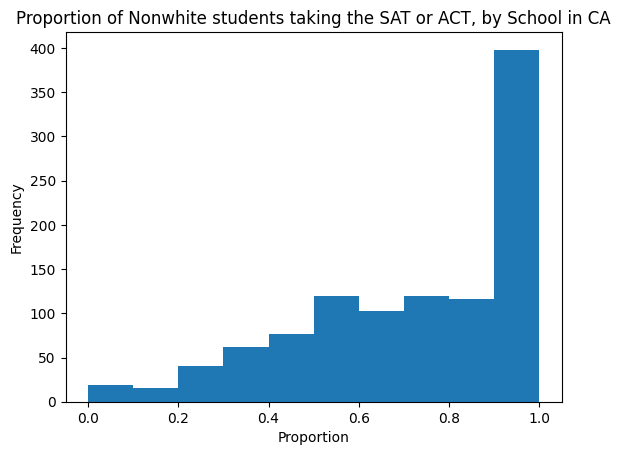

In [12]:
# plotting proportion of Nonwhite students taking SAT/ACT
nonwhite_prop_ca = (dat_ca['Total Nonwhite']/dat_ca['Total'])
plt.hist(nonwhite_prop_ca)
plt.title('Proportion of Nonwhite students taking the SAT or ACT, by School in CA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of non-white students per school taking the SAT or ACT in California, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is right-skewed, meaning that there tends to be higher proportions of non-white students taking the SAT and ACT per schools.

Text(0, 0.5, 'Frequency')

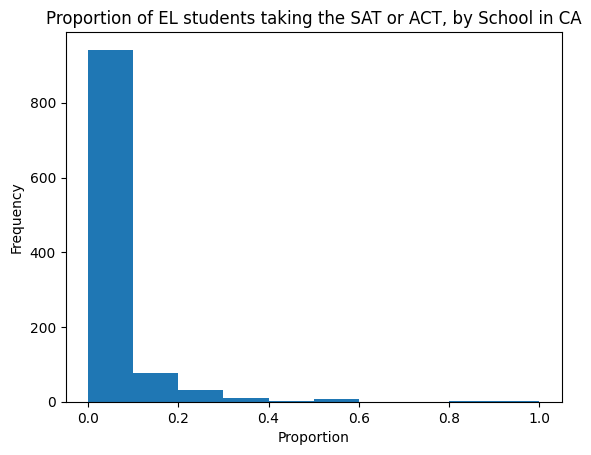

In [13]:
# plotting proportion of EL students taking the SAT/ACT
EL_prop_ca = dat_ca['Total EL']/dat_ca['Total']
plt.hist(EL_prop_ca)
plt.title('Proportion of EL students taking the SAT or ACT, by School in CA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of EL (English Learning) students per school taking the SAT and ACT in California, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, meaning that there tend to be much lower proportions of EL Students students taking the SAT and ACT in schools.

Text(0, 0.5, 'Frequency')

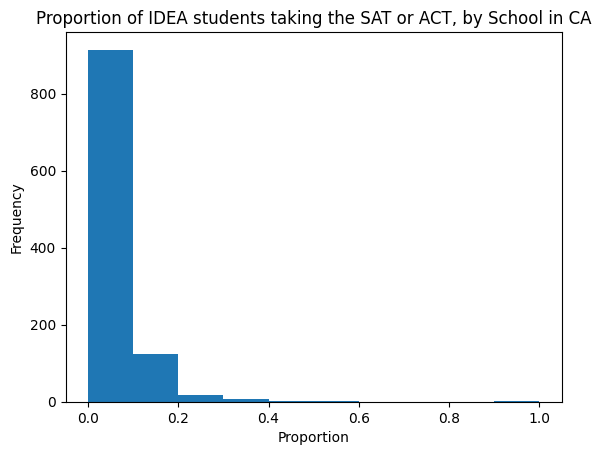

In [14]:
# Plotting the proportion of IDEA students taking the SAT/ACT
IDEA_prop_ca = dat_ca['Total IDEA']/dat_ca['Total']
plt.hist(IDEA_prop_ca)
plt.title('Proportion of IDEA students taking the SAT or ACT, by School in CA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of IDEA (Individuals with Disabilities) students per school taking the SAT and ACT in California, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, demonstrating that there tend to be much lower proportions of IDEA Students students taking the SAT and ACT in schools.

#EDA: New Mexico

In [15]:
# locating New Mexico data
dat_nm = dat.loc[(dat['State'] == 'NM')]

In [16]:
# descriptive statistics for numerical variables
dat_nm.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,Total Female,EL Male,EL Female,IDEA Male,IDEA Female,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,187.000000,187.000000,187.000000,187.000000,187.000000,187.000000,187.000000,187.000000,187.000000,187.000000,...,187.000000,187.000000,187.000000,187.000000,187.000000,187.00000,187.000000,187.000000,187.000000,187.000000
mean,38.759358,37.903743,7.417112,7.245989,0.951872,0.914439,0.080214,0.090909,1.256684,1.139037,...,61.144385,12.946524,10.935829,11.224599,6.737968,123.73262,25.187166,98.545455,23.882353,17.962567
std,56.715389,54.253599,17.715716,16.315881,3.354156,2.519420,0.326243,0.323410,2.484012,2.571959,...,74.972436,22.401933,19.682047,15.840361,9.628073,151.84253,39.989814,124.452832,41.587801,24.880439
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,4.00000,0.000000,1.000000,0.000000,0.000000
25%,4.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,13.000000,0.000000,0.000000,1.000000,1.000000,25.50000,2.000000,18.000000,1.000000,2.000000
50%,13.000000,14.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,25.000000,3.000000,3.000000,4.000000,3.000000,49.00000,10.000000,41.000000,6.000000,7.000000
75%,47.500000,44.500000,5.000000,6.500000,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,...,82.000000,15.000000,11.500000,13.500000,9.000000,165.00000,25.000000,129.500000,28.000000,23.000000
max,307.000000,265.000000,121.000000,107.000000,40.000000,27.000000,2.000000,2.000000,17.000000,19.000000,...,346.000000,124.000000,122.000000,73.000000,52.000000,662.00000,232.000000,566.000000,246.000000,112.000000


Text(0, 0.5, 'Frequency')

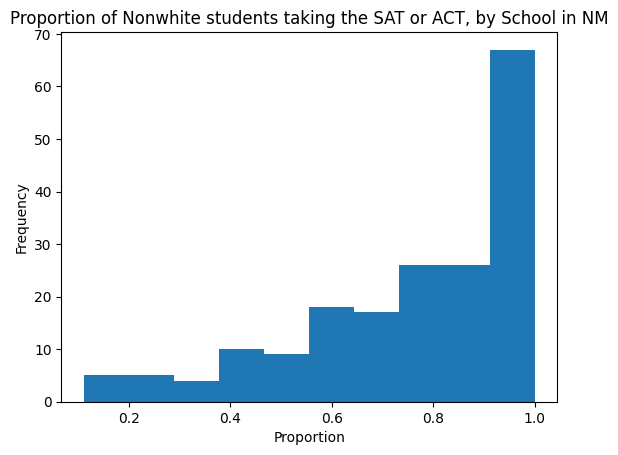

In [17]:
# proportion of nonwhite students
nonwhite_prop_nm = dat_nm['Total Nonwhite']/dat_nm['Total']
plt.hist(nonwhite_prop_nm)
plt.title('Proportion of Nonwhite students taking the SAT or ACT, by School in NM')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of non-white students per school taking the SAT or ACT in New Mexico, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is right-skewed, meaning that there tends to be higher proportions of non-white students taking the SAT and ACT per schools.

Text(0, 0.5, 'Frequency')

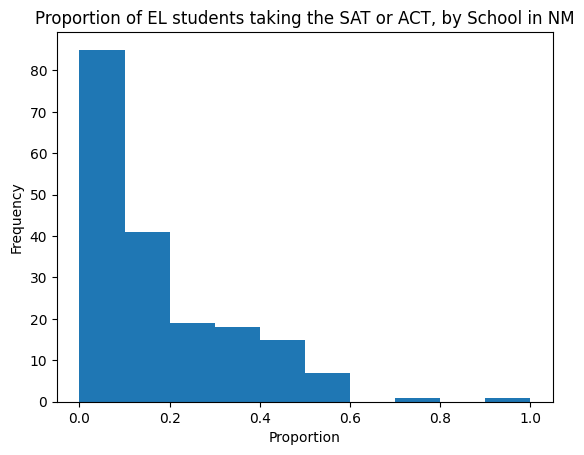

In [18]:
# proportion of EL students
EL_prop_nm = dat_nm['Total EL']/dat_nm['Total']
plt.hist(EL_prop_nm)
plt.title('Proportion of EL students taking the SAT or ACT, by School in NM')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of EL (English Learning) students per school taking the SAT and ACT in New Mexico, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, meaning that there tend to be much lower proportions of EL Students students taking the SAT and ACT in schools.

Text(0, 0.5, 'Frequency')

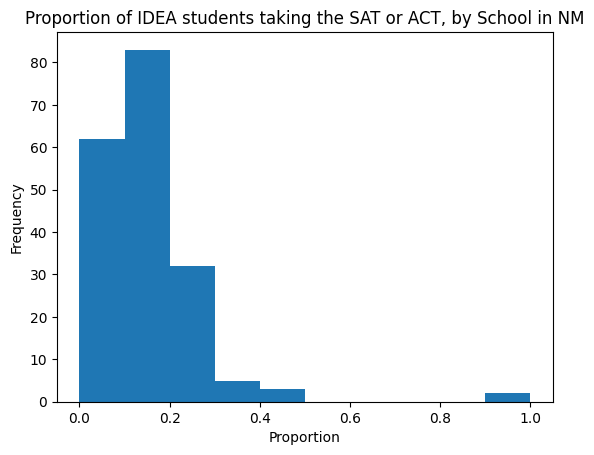

In [19]:
# proportion of IDEA students
IDEA_prop_nm = dat_nm['Total IDEA']/dat_nm['Total']
plt.hist(IDEA_prop_nm)
plt.title('Proportion of IDEA students taking the SAT or ACT, by School in NM')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of IDEA (Individuals with Disabilities) students per school taking the SAT and ACT in New Mexico, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is left-skewed with a mode at the 0.1-0.2 range, demonstrating that there tend to be much lower proportions of IDEA Students students taking the SAT and ACT in schools.

#EDA: Texas

In [20]:
# separating Texas data
dat_tx = dat.loc[(dat['State'] == 'TX')]

In [21]:
# descriptive statistics
dat_tx.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,Total Female,EL Male,EL Female,IDEA Male,IDEA Female,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,...,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000,1653.000000
mean,51.281307,54.963702,0.327889,0.320024,8.395644,8.221416,0.155475,0.174834,13.044767,14.044162,...,109.098609,16.733212,15.814882,8.165759,5.110103,213.003630,55.820932,157.182698,32.548094,13.275862
std,73.640381,76.783964,0.795068,0.832783,29.406861,29.171935,0.685832,0.736654,28.620172,31.052928,...,139.512696,30.055108,28.289272,12.267760,7.604636,276.416604,101.148283,215.735926,57.925358,19.448731
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,4.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,14.000000,0.000000,0.000000,0.000000,0.000000,25.000000,4.000000,11.000000,1.000000,1.000000
50%,17.000000,19.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2.000000,2.000000,...,45.000000,3.000000,3.000000,2.000000,2.000000,87.000000,16.000000,52.000000,6.000000,4.000000
75%,74.000000,79.000000,0.000000,0.000000,3.000000,3.000000,0.000000,0.000000,10.000000,12.000000,...,149.000000,21.000000,20.000000,11.000000,7.000000,286.000000,54.000000,219.000000,40.000000,19.000000
max,492.000000,498.000000,6.000000,10.000000,471.000000,472.000000,17.000000,11.000000,254.000000,262.000000,...,1108.000000,278.000000,276.000000,129.000000,87.000000,2202.000000,872.000000,1420.000000,554.000000,216.000000


Text(0, 0.5, 'Frequency')

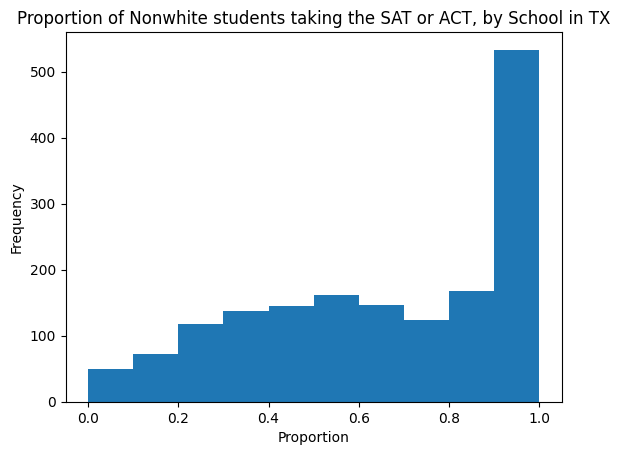

In [22]:
# nonwhite students
nonwhite_prop_tx = dat_tx['Total Nonwhite']/dat_tx['Total']
plt.hist(nonwhite_prop_tx)
plt.title('Proportion of Nonwhite students taking the SAT or ACT, by School in TX')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of non-white students per school taking the SAT or ACT in Texas, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is right-skewed, meaning that there tends to be higher proportions of non-white students taking the SAT and ACT per schools.

Text(0, 0.5, 'Frequency')

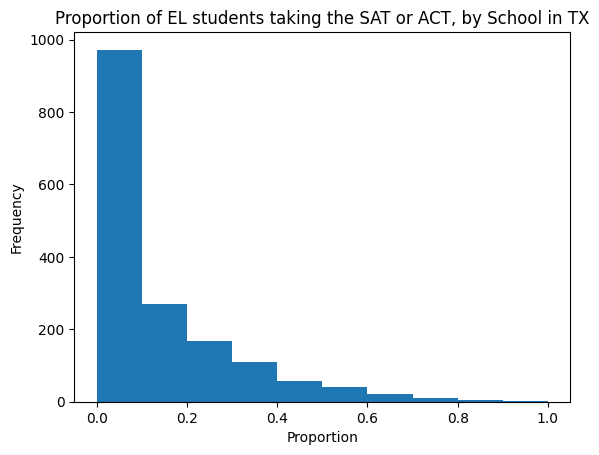

In [23]:
# EL students
EL_prop_tx = dat_tx['Total EL']/dat_tx['Total']
plt.hist(EL_prop_tx)
plt.title('Proportion of EL students taking the SAT or ACT, by School in TX')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of EL (English Learning) students per school taking the SAT and ACT in Texas, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, meaning that there tends to be much lower proportions of EL Students students taking the SAT and ACT in schools.

Text(0, 0.5, 'Frequency')

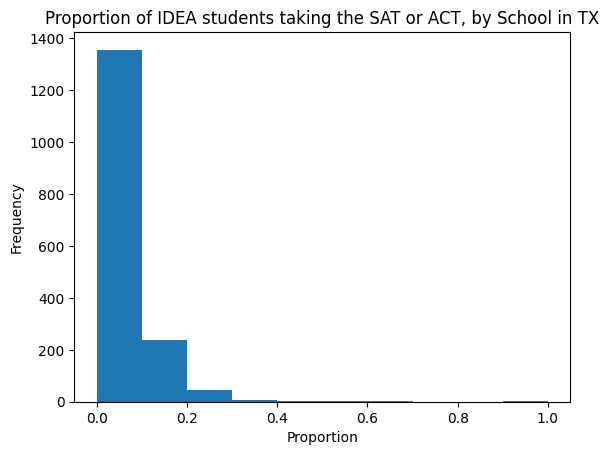

In [24]:
# IDEA students
IDEA_prop_tx = dat_tx['Total IDEA']/dat_tx['Total']
plt.hist(IDEA_prop_tx)
plt.title('Proportion of IDEA students taking the SAT or ACT, by School in TX')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of IDEA (Individuals with Disabilities) students per school taking the SAT and ACT in Texas, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, demonstrating that there tend to be much lower proportions of IDEA Students students taking the SAT and ACT in schools.

#EDA: Massachusetts

In [25]:
# Separating Massachusetts Data
dat_ma = dat.loc[(dat['State'] == 'MA')]

In [26]:
# Descriptive statistics
dat_ma.describe()

,Hispanic Male,Hispanic Female,Native American Male,Native American Female,Asian Male,Asian Female,Pacific Islander Male,Pacific Islander Female,Black Male,Black Female,...,Total Female,EL Male,EL Female,IDEA Male,IDEA Female,Total,Total White,Total Nonwhite,Total EL,Total IDEA
count,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,...,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000,338.000000
mean,10.041420,11.322485,0.174556,0.147929,9.047337,9.556213,0.053254,0.044379,5.529586,6.656805,...,73.278107,2.857988,2.399408,5.967456,4.295858,140.254438,82.272189,57.982249,5.257396,10.263314
std,22.101561,22.587374,0.622766,0.518511,20.000092,21.957974,0.237703,0.233248,10.002701,11.509020,...,77.571329,9.687580,8.366792,8.799892,6.715148,150.161082,92.364890,85.237561,17.915115,14.895040
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,0.000000,0.000000,0.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000
25%,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,24.000000,0.000000,0.000000,1.000000,0.000000,44.000000,19.000000,8.250000,0.000000,1.000000
50%,3.000000,4.000000,0.000000,0.000000,2.000000,2.000000,0.000000,0.000000,2.000000,2.000000,...,48.000000,0.000000,0.000000,3.000000,2.000000,93.000000,55.500000,23.000000,0.000000,5.000000
75%,8.750000,11.000000,0.000000,0.000000,7.000000,7.750000,0.000000,0.000000,5.000000,7.750000,...,93.750000,1.000000,1.000000,9.000000,6.000000,182.750000,114.000000,73.750000,2.000000,15.000000
max,223.000000,208.000000,6.000000,6.000000,162.000000,221.000000,2.000000,2.000000,64.000000,75.000000,...,747.000000,114.000000,100.000000,105.000000,65.000000,1431.000000,737.000000,694.000000,214.000000,170.000000


Text(0, 0.5, 'Frequency')

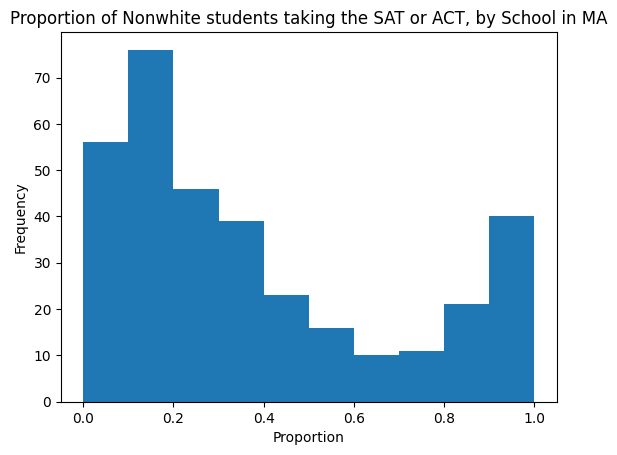

In [27]:
# nonwhite students
nonwhite_prop_ma = dat_ma['Total Nonwhite']/dat_ma['Total']
plt.hist(nonwhite_prop_ma)
plt.title('Proportion of Nonwhite students taking the SAT or ACT, by School in MA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of non-white students per school taking the SAT or ACT in Massachusetts, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is bimodal at around 0.1-0.2 and 0.1-1.0, but has a higher mode at the 0.1-0.2 range.

Text(0, 0.5, 'Frequency')

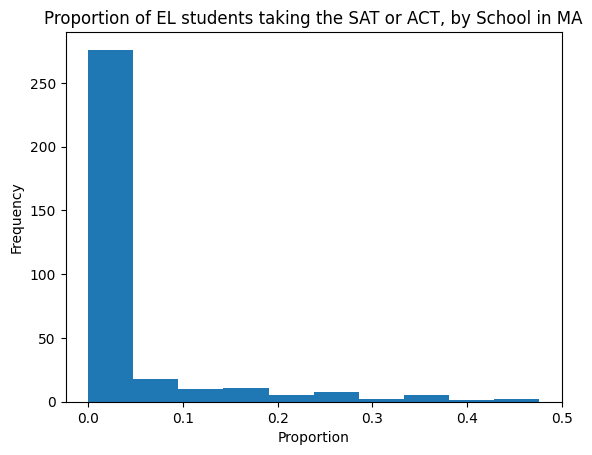

In [28]:
# EL students
EL_prop_ma = dat_ma['Total EL']/dat_ma['Total']
plt.hist(EL_prop_ma)
plt.title('Proportion of EL students taking the SAT or ACT, by School in MA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of EL (English Learning) students per school taking the SAT and ACT in Massachusetts, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is heavily left-skewed, meaning that there tends to be much lower proportions of EL Students students taking the SAT and ACT in schools.

Text(0, 0.5, 'Frequency')

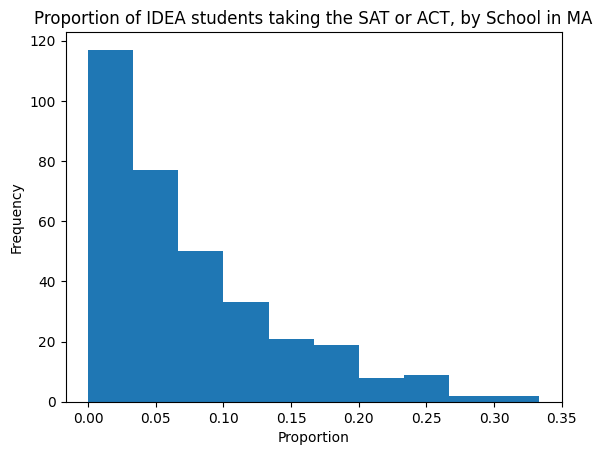

In [29]:
# IDEA students
IDEA_prop_ma = dat_ma['Total IDEA']/dat_ma['Total']
plt.hist(IDEA_prop_ma)
plt.title('Proportion of IDEA students taking the SAT or ACT, by School in MA')
plt.xlabel('Proportion')
plt.ylabel('Frequency')

**Alt Text**: A histogram displaying the proportions of IDEA (Individuals with Disabilities) students per school taking the SAT and ACT in Masachussets, with an X-axis of the proportion values, y-axis of frequency, and bin size of 0.1. This histogram is left-skewed (though the mode is not quite as extreme as in the other observed states) demonstrating that there tend to be much lower proportions of IDEA Students students taking the SAT and ACT in schools.

# Concatenating and Exporting Data

In [30]:
ca_nm_tx_ma = [dat_ca, dat_nm, dat_tx, dat_ma]
dat_ca_nm_tx_ma = pd.concat(ca_nm_tx_ma)

In [31]:
dat_ca_nm_tx_ma.to_csv('SAT and ACT Cleaned.csv', index = False)